# CircularAperturePSF 核验: Airy / 离焦 / 像差 / 渲染一致性

用新增的 `psf_at(z)` 小工具(不依赖渲染)对照:

- **衍射极限 Airy**(z = focus 处, 第一暗环 r ≈ 0.61·λ/NA, 与解析式对照)
- **离焦形变**(z 偏离 focus 时环状扩散)
- **静态像差**(Zernike 像散 Z5/Z6 → 非对称 PSF)
- **渲染一致性**(单分子 render ↔ psf_at; 多分子 vs GaussianPSF)

运行前提: cwd = Simulation_Smile, `simulation_smile` 可导入。

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j1
from simulation_smile.optics import CircularAperturePSF, GaussianPSF
from simulation_smile.datatypes import EmitterSet, FieldOfView

# --- 中文字体: 让图内中文标题正常显示 (避免 DejaVu Sans 缺字形警告) ---
import matplotlib
from matplotlib import font_manager
_CJK_FONTS = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC',
              'Source Han Sans SC', 'Arial Unicode MS', 'PingFang SC', 'SimSun']
_names = {f.name for f in font_manager.fontManager.ttflist}
_zh = next((f for f in _CJK_FONTS if f in _names), None)
if _zh:
    matplotlib.rcParams['font.sans-serif'] = [_zh, 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False   # 避免负号显示为方块

na, wl = 1.49, 680.0          # NA=1.49 油浸, λ=680 nm


def kernel_axis(K, spacing):
    """PSF 核的坐标轴 (nm), 原点取 fftshift DC 索引 n//2。"""
    n = K.shape[0]
    return (np.arange(n) - n // 2) * spacing


def airy_profile(r):
    """解析衍射极限 Airy (偶函数, 用 |r|): I(r) = [2 J1(x)/x]^2, x = 2π·NA·|r|/λ。"""
    x = 2 * np.pi * na * np.abs(r) / wl
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where(x > 0, (2 * j1(x) / x) ** 2, 1.0)


In [7]:
psf = CircularAperturePSF(na=na, wavelength=wl,
                          pupil_size=128, oversample=4, focus=0.0)
print('kernel_spacing =', round(psf.kernel_spacing, 2), 'nm')
print('nyquist_pixel  =', round(psf.nyquist_pixel, 2), 'nm')
print('defocus_waves_per_nm =', round(psf.defocus_waves_per_nm, 6), 'waves/nm')

kernel_spacing = 57.05 nm
nyquist_pixel  = 228.19 nm
defocus_waves_per_nm = 0.001632 waves/nm


## 1. 衍射极限 Airy 校验 (z = focus)

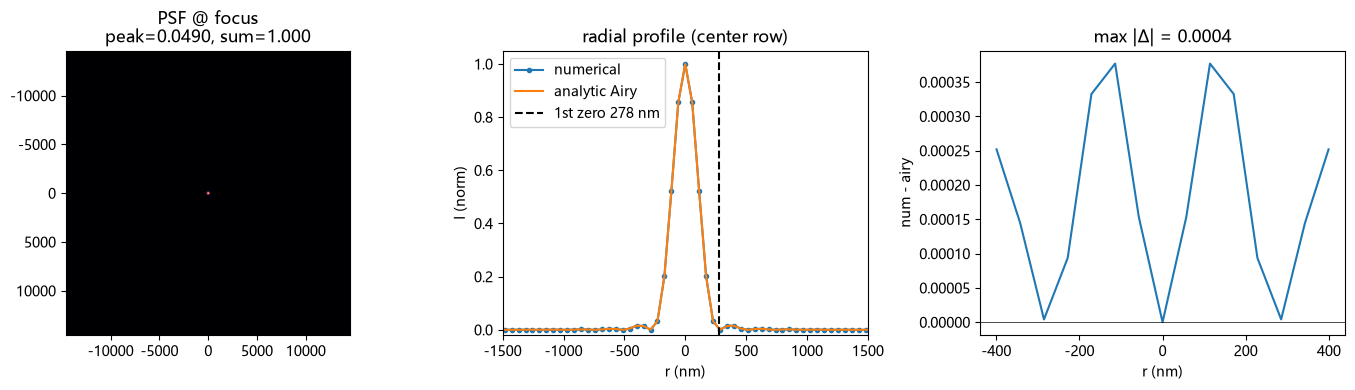

第一暗环: 理论 278.4 nm | 数值(最近采样 285 nm) I=0.0004


In [8]:
K0 = psf.psf_at(0.0)
n = K0.shape[0]
h = psf.kernel_spacing
ax = kernel_axis(K0, h)
row = K0[n // 2] / K0[n // 2, n // 2]
airy = airy_profile(ax)

r_airy = 0.61 * wl / na            # 理论第一暗环
i0 = int(np.argmin(np.abs(ax - r_airy)))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(K0, cmap='inferno', extent=[ax.min(), ax.max(), ax.max(), ax.min()])
axes[0].set_title(f'PSF @ focus\npeak={K0.max():.4f}, sum={K0.sum():.3f}')
axes[1].plot(ax, row, 'o-', ms=3, label='numerical')
axes[1].plot(ax, airy, label='analytic Airy')
axes[1].axvline(r_airy, color='k', ls='--', label=f'1st zero {r_airy:.0f} nm')
axes[1].set_xlim(-1500, 1500); axes[1].set_ylim(-0.02, 1.05)
axes[1].set_xlabel('r (nm)'); axes[1].set_ylabel('I (norm)'); axes[1].legend()
axes[1].set_title('radial profile (center row)')
mask = np.abs(ax) < 1.5 * r_airy
axes[2].plot(ax[mask], row[mask] - airy[mask]); axes[2].axhline(0, color='k', lw=0.5)
axes[2].set_title(f'max |Δ| = {np.abs(row[mask]-airy[mask]).max():.4f}')
axes[2].set_xlabel('r (nm)'); axes[2].set_ylabel('num - airy')
plt.tight_layout(); plt.show()
print(f'第一暗环: 理论 {r_airy:.1f} nm | 数值(最近采样 {ax[i0]:.0f} nm) I={row[i0]:.4f}')

## 2. 离焦形变 (z 扫描)

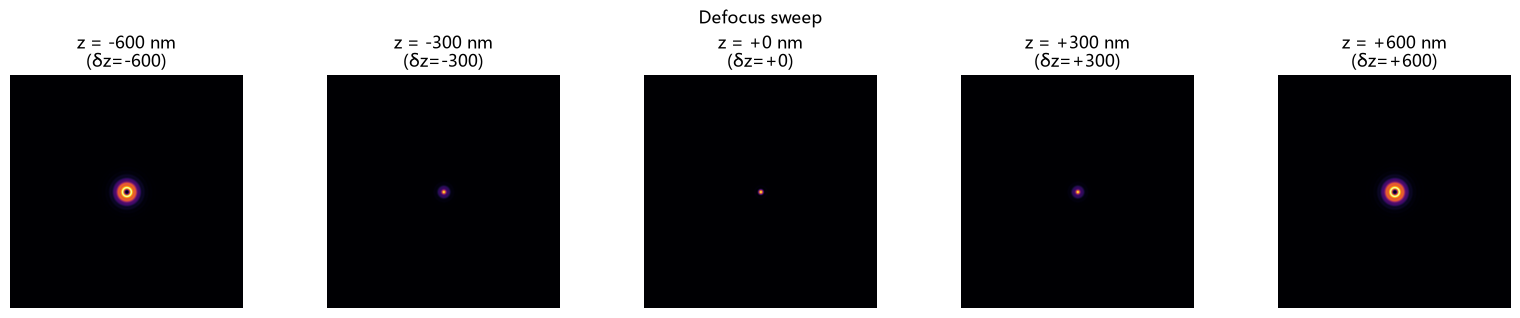

In [9]:
zs = [-600, -300, 0, 300, 600]
crop = 128
fig, axes = plt.subplots(1, len(zs), figsize=(3.2 * len(zs), 3.2))
for ax_, z in zip(axes, zs):
    K = psf.psf_at(z)
    Kc = K[n // 2 - crop:n // 2 + crop, n // 2 - crop:n // 2 + crop]
    ax_.imshow(Kc, cmap='inferno')
    ax_.set_title(f'z = {z:+d} nm\n(δz={z-psf.focus:+.0f})')
    ax_.axis('off')
plt.suptitle('Defocus sweep'); plt.tight_layout(); plt.show()

## 3. 静态像差 (柱面镜像散 Z5, Z6)

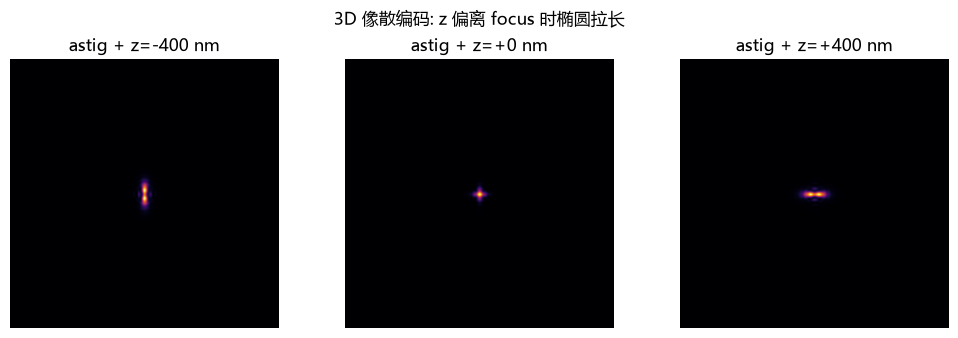

z=±400 处 x/y 剖面差 = 0.892 (椭圆, 编码 z) | z=0 处 = 0.000 (对称)


In [10]:
psf_ast = CircularAperturePSF(na=na, wavelength=wl,
                              zernike={6: 0.15},        # 固定像散 (柱面镜)
                              pupil_size=128, oversample=4, focus=0.0)
zs_ast = [-400, 0, 400]
crop = 128
fig, axes = plt.subplots(1, len(zs_ast), figsize=(3.4 * len(zs_ast), 3.4))
for ax_, z in zip(axes, zs_ast):
    K = psf_ast.psf_at(z)
    nk = K.shape[0]
    Kc = K[nk // 2 - crop:nk // 2 + crop, nk // 2 - crop:nk // 2 + crop]
    ax_.imshow(Kc, cmap='inferno')
    ax_.set_title(f'astig + z={z:+d} nm')
    ax_.axis('off')
plt.suptitle('3D 像散编码: z 偏离 focus 时椭圆拉长')
plt.tight_layout(); plt.show()

# 定量: z=±400 时 x/y 剖面应明显不同 (椭圆), z=0 时对称
Kp = psf_ast.psf_at(400.0); Km = psf_ast.psf_at(-400.0); K0a = psf_ast.psf_at(0.0)
mid = Kp.shape[0] // 2
asym_z = float(np.abs(Kp[mid] / Kp.max() - Kp[:, mid] / Kp.max()).max())
asym_0 = float(np.abs(K0a[mid] / K0a.max() - K0a[:, mid] / K0a.max()).max())
print(f'z=±400 处 x/y 剖面差 = {asym_z:.3f} (椭圆, 编码 z) | z=0 处 = {asym_0:.3f} (对称)')


## 4. 3D 像散 (柱面镜): 固定像散 + 离焦编码 z

Z6 像散单独在 z=0(最佳焦点) 时 PSF 是对称的; 3D 编码在于**固定像散 + 离焦**:
z 偏离 focus 时椭圆拉长/旋转, 这就是柱面镜 3D 定位的原理。


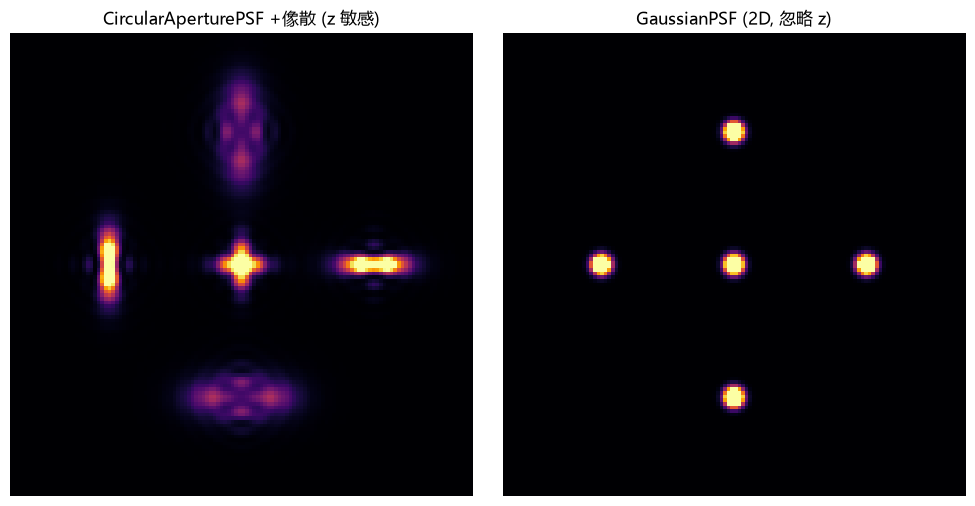

In [16]:
fov = FieldOfView(height=128, width=128, pixel_size=60.0)
# 十字排列: 中心=聚焦, 四臂分别 ±300/±600 nm (间距 2200 nm, 约 37 px)
# 用 psf_ast (固定像散 Z6) 渲染: 左图展示"像散 + 离焦"的椭圆编码 z, 与高斯对照
cx = cy = 3840.0
d = 2200.0
xyz = np.array([
    [cx,       cy,       0.0],    # 中心, z=0 聚焦
    [cx + d,   cy,       300.0],  # 右,  z=+300
    [cx - d,   cy,      -300.0],  # 左,  z=-300
    [cx,       cy + d,   600.0],  # 下,  z=+600
    [cx,       cy - d,  -600.0],  # 上,  z=-600
], dtype=float)
emitters = EmitterSet(xyz=xyz, brightness=np.full(5, 2000.0))
ph = np.full((5, 1), 2000.0)

img_ast = psf_ast.render(emitters, ph, fov)[0]          # 像散 + 离焦
img_gauss = GaussianPSF(sigma_nm=100.0).render(emitters, ph, fov)[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
# 分位数拉伸: 单分子动态范围大(亮核 vs 暗椭圆环), 直接 imshow 会淹没暗斑
axes[0].imshow(img_ast, cmap='inferno', vmax=np.percentile(img_ast, 99.5))
axes[0].set_title('CircularAperturePSF +像散 (z 敏感)')
axes[1].imshow(img_gauss, cmap='inferno', vmax=np.percentile(img_gauss, 99.5))
axes[1].set_title('GaussianPSF (2D, 忽略 z)')
for ax_ in axes: ax_.axis('off')
plt.tight_layout(); plt.show()


## 5. 单分子渲染 ↔ psf_at 一致性 (能量守恒 + 峰值位置 + 形状)

In [17]:
from scipy.ndimage import map_coordinates

fov1 = FieldOfView(height=512, width=512, pixel_size=57.0)
cx = cy = 512 * 57.0 / 2.0
h = psf.kernel_spacing
flux = (fov1.pixel_size / h) ** 2

for z in [0.0, 300.0, -600.0]:
    e1 = EmitterSet(xyz=np.array([[cx, cy, z]]), brightness=np.array([1.0]))
    img = psf.render(e1, np.ones((1, 1)), fov1)[0]     # 单光子渲染
    K = psf.psf_at(z)
    iy, ix = np.unravel_index(np.argmax(img), img.shape)

    # 独立重采样 psf_at 到 FOV 像素网格 (map_coordinates, 与 render 同一几何)
    n = K.shape[0]
    kc0 = (0 - n // 2) * h                             # 核索引 0 对应的 nm 坐标
    rr = (np.arange(fov1.height) + 0.5) * fov1.pixel_size - cy
    cc = (np.arange(fov1.width) + 0.5) * fov1.pixel_size - cx
    fx, fy = (cc - kc0) / h, (rr - kc0) / h
    gx, gy = np.meshgrid(fx, fy)
    expected = map_coordinates(K, [gy, gx], order=1, mode='constant', cval=0.0) * flux
    diff = float(np.abs(img - expected).max())

    print(f'z={z:+7.1f} nm | 能量={img.sum():.4f} | 峰值像素=({ix},{iy}) '
          f'(应≈256,256) | render vs 独立重采样最大差={diff:.2e}')


z=   +0.0 nm | 能量=1.0000 | 峰值像素=(256,256) (应≈256,256) | render vs 独立重采样最大差=5.22e-14
z= +300.0 nm | 能量=1.0000 | 峰值像素=(256,256) (应≈256,256) | render vs 独立重采样最大差=1.93e-14
z= -600.0 nm | 能量=1.0000 | 峰值像素=(259,259) (应≈256,256) | render vs 独立重采样最大差=3.28e-04
